<a href="https://colab.research.google.com/github/vip21-000/data_analytics/blob/main/lab_%2B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  localized_name  picks
0         Rubick   6561
1           Tiny   5877
2         Jakiro   5611
3   Shadow Fiend   5217
4  Queen of Pain   5071
5      Ogre Magi   5024
6          Pudge   4688
7           Tusk   4681
8           Mars   4620
9  Dragon Knight   4585


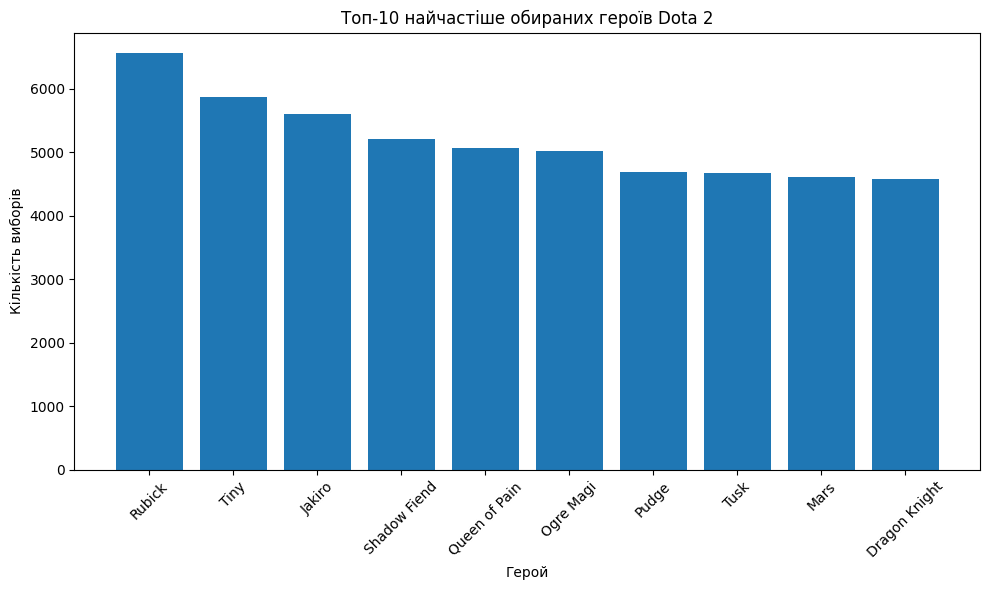

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантажуємо дані про піки та бани
picks_bans = pd.read_csv("/content/picks_bans.csv")

# Завантажуємо інформацію про героїв
heroes = pd.read_csv("/content/Constants.Heroes.csv")

# Залишаємо тільки вибори героїв
picks = picks_bans[picks_bans["is_pick"] == True]

# Рахуємо, скільки разів кожного героя обрали
popular_heroes = picks["hero_id"].value_counts().reset_index()

popular_heroes.columns = ["hero_id", "picks"]

# Додаємо назву героя
popular_heroes = popular_heroes.merge(
    heroes[["id", "localized_name"]],
    left_on="hero_id",
    right_on="id",
    how="left"
)

# Беремо топ-10
top_10 = popular_heroes.head(10)

# Виводимо таблицю
print(top_10[["localized_name", "picks"]])

# Будуємо Bar Chart
plt.figure(figsize=(10, 6))

plt.bar(top_10["localized_name"], top_10["picks"])

plt.title("Топ-10 найчастіше обираних героїв Dota 2 на ")
plt.xlabel("Герой")
plt.ylabel("Кількість виборів")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()